<a href="https://colab.research.google.com/github/192565074simats-code/MLA0201/blob/main/Experiment_18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IRIS TRAINING DATASET
   Sepal Length  Sepal Width Species
0           5.1          3.5  setosa
1           4.9          3.0  setosa
2           4.7          3.2  setosa
3           4.6          3.1  setosa
4           5.0          3.6  setosa
5           5.4          3.9  setosa
6           4.6          3.4  setosa
7           5.0          3.4  setosa
8           4.4          2.9  setosa
9           4.9          3.1  setosa

Dataset Shape: (100, 3)

Training Samples: 80
Testing Samples: 20

Perceptron Model Trained Successfully!

CLASSIFICATION RESULTS
   Actual Species Predicted Species
0      versicolor            setosa
1      versicolor        versicolor
2      versicolor        versicolor
3      versicolor        versicolor
4          setosa            setosa
5          setosa            setosa
6          setosa            setosa
7      versicolor        versicolor
8          setosa        versicolor
9          setosa            setosa
10         setosa            setosa
11     v

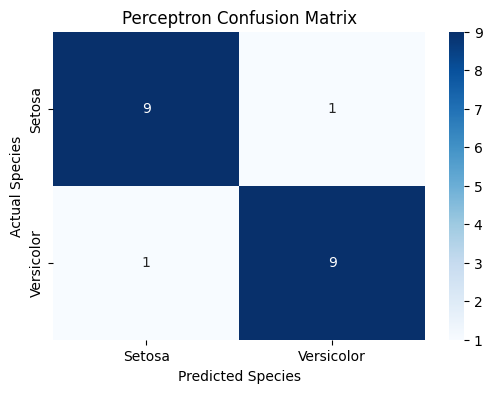

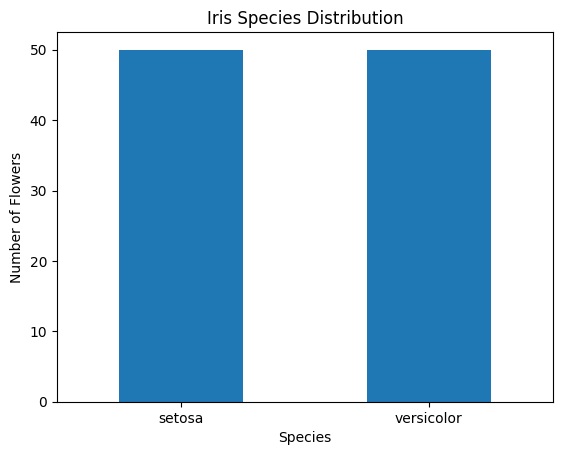

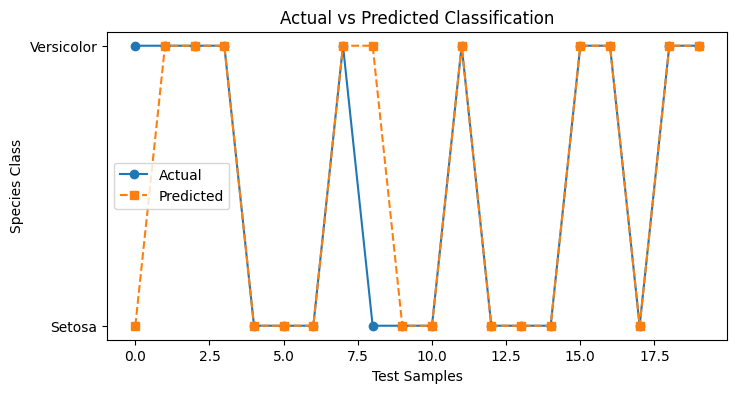

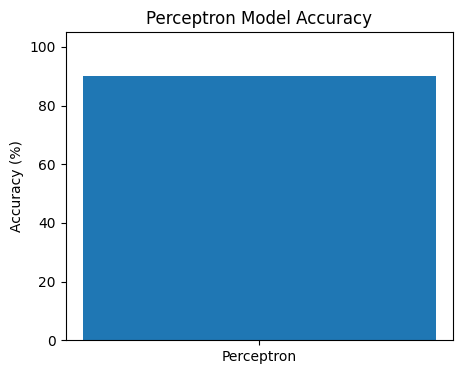


NEW FLOWER PREDICTION
Sepal Length: 5.1
Sepal Width: 3.5
Predicted Species: setosa


In [1]:
# EXPERIMENT 18: PERCEPTRON-BASED IRIS CLASSIFICATION

# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Step 2: Load Iris dataset
iris = load_iris()

# Select Setosa and Versicolor
X = iris.data[:100, :2]
y = iris.target[:100]

df = pd.DataFrame(
    X, columns=['Sepal Length', 'Sepal Width']
)

df['Species'] = [
    iris.target_names[i] for i in y
]

print("IRIS TRAINING DATASET")
print(df.head(10))

print("\nDataset Shape:", df.shape)

# Step 3: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# Step 4: Feature scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 5: Train Perceptron model
model = Perceptron(
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)

print("\nPerceptron Model Trained Successfully!")

# Step 6: Prediction
y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual Species': iris.target_names[y_test],
    'Predicted Species': iris.target_names[y_pred]
})

print("\nCLASSIFICATION RESULTS")
print(results)

# Step 7: Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:",
      round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['Setosa', 'Versicolor']
))

# Step 8: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Setosa', 'Versicolor'],
    yticklabels=['Setosa', 'Versicolor']
)

plt.title("Perceptron Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

# Step 9: Species Distribution Graph
df['Species'].value_counts().plot(kind='bar')

plt.title("Iris Species Distribution")
plt.xlabel("Species")
plt.ylabel("Number of Flowers")
plt.xticks(rotation=0)
plt.show()

# Step 10: Actual vs Predicted Graph
plt.figure(figsize=(8, 4))

plt.plot(y_test, 'o-', label='Actual')
plt.plot(y_pred, 's--', label='Predicted')

plt.title("Actual vs Predicted Classification")
plt.xlabel("Test Samples")
plt.ylabel("Species Class")
plt.yticks([0, 1], ['Setosa', 'Versicolor'])
plt.legend()
plt.show()

# Step 11: Accuracy Graph
plt.figure(figsize=(5, 4))

plt.bar(['Perceptron'], [accuracy * 100])

plt.title("Perceptron Model Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)
plt.show()

# Step 12: Predict New Flower
new_flower = [[5.1, 3.5]]

new_flower_scaled = scaler.transform(new_flower)

prediction = model.predict(new_flower_scaled)

print("\nNEW FLOWER PREDICTION")
print("Sepal Length: 5.1")
print("Sepal Width: 3.5")

print("Predicted Species:",
      iris.target_names[prediction[0]])